# Questions & Solutions

## Can I use a geotif to derive classes & maps?

### Approach — is a single GeoTIFF enough to derive land-cover labels?

Before committing to a labelling strategy, we probe one UNDP land-cover tile
directly: its dimensions, bounds, transform and CRS. The reasoning is that if these
10 m class tiles align cleanly with Sentinel-2's grid and CRS, they can serve as
**ready-made pixel labels** for Kenya — avoiding any manual annotation. The cells
below are deliberately exploratory (read-only inspection) to confirm that before
building anything on top of them.

In [ ]:
import pandas as pd
import geopandas as gpd
import shapely as sh
import rasterio
from rasterio.plot import show

In [ ]:
dataset = rasterio.open(r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif')
dataset.count   #how many bands

1

In [ ]:
print(f'width:{dataset.width}, height:{dataset.height}')

width:66794, height:88550


In [ ]:
dataset.bounds

BoundingBox(left=166030.0, bottom=9114500.0, right=833970.0, top=10000000.0)

In [ ]:
dataset.transform

Affine(10.0, 0.0, 166030.0,
       0.0, -10.0, 10000000.0)

In [ ]:
dataset.crs

CRS.from_wkt('PROJCS["WGS 84 / UTM zone 36S",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",33],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",10000000],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32736"]]')

(2000, 2000) uint8 1 11


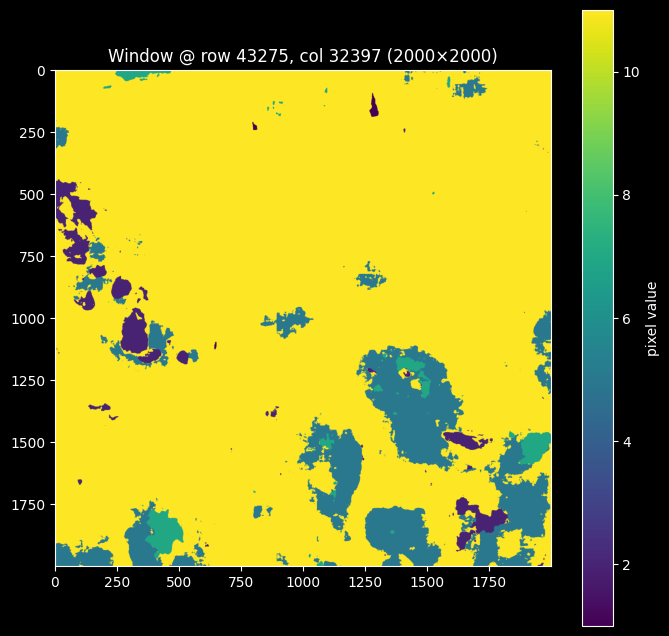

In [ ]:
import rasterio
from rasterio.windows import Window
import matplotlib.pyplot as plt

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as dataset:
    # Take a 2000 x 2000 pixel chunk from the centre of the image
    win_size = 2000
    col_off = dataset.width  // 2 - win_size // 2
    row_off = dataset.height // 2 - win_size // 2
    window = Window(col_off, row_off, win_size, win_size)

    sample = dataset.read(1, window=window)   # band 1 only, just this window
    print(sample.shape, sample.dtype, sample.min(), sample.max())

plt.figure(figsize=(8, 8))
plt.imshow(sample, cmap='viridis')
plt.colorbar(label='pixel value')
plt.title(f'Window @ row {row_off}, col {col_off} ({win_size}×{win_size})')
plt.show()

(885, 667)


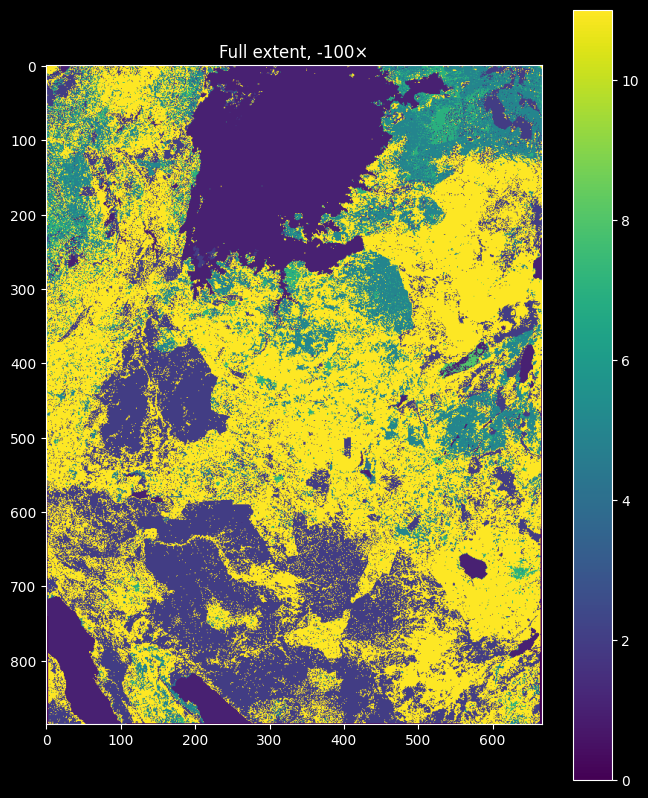

In [ ]:
import rasterio
import matplotlib.pyplot as plt

with rasterio.open(fp) as dataset:
    scale = 100  # 1 output pixel per 100 source pixels
    thumb = dataset.read(1,
                         out_shape=(dataset.height // scale, dataset.width // scale)
    )
    print(thumb.shape)   # ~ (885, 667)

plt.figure(figsize=(8, 10))
plt.imshow(thumb, cmap='viridis')
plt.colorbar()
plt.title('Full extent, -100×')
plt.show()

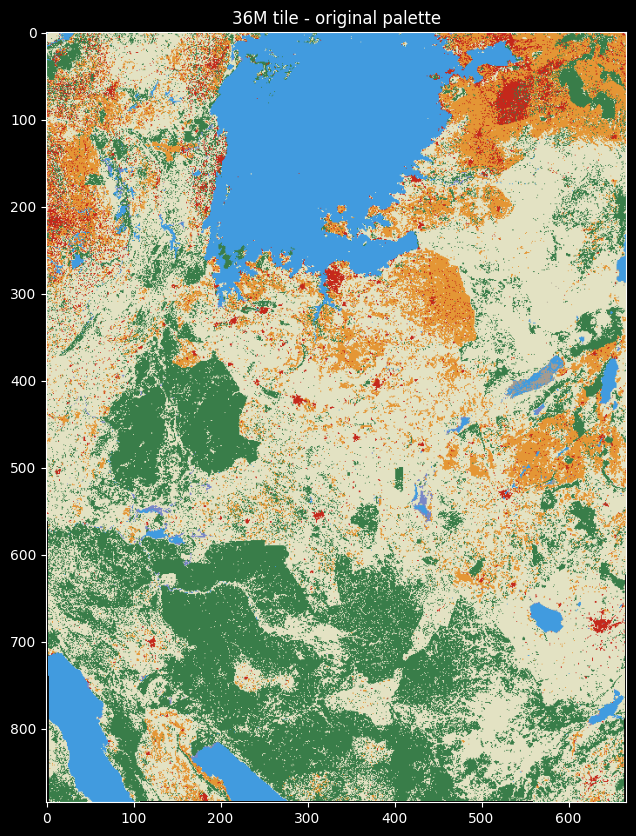

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)                       # {value: (r,g,b,a)}

# build a lookup table and map class values -> RGB
lut = np.zeros((256, 4), dtype=np.uint8)
for val, rgba in cmap.items():
    lut[val] = rgba
rgb = lut[thumb]                                # (H, W, 4) RGBA image

plt.figure(figsize=(8, 10))
plt.imshow(rgb)
plt.title('36M tile - original palette')
plt.show()


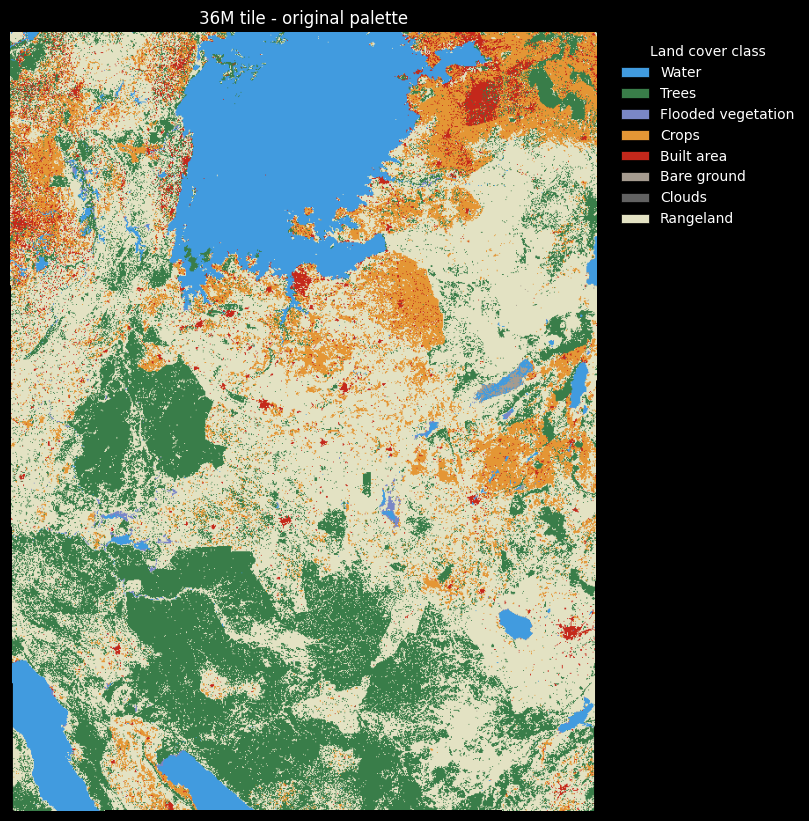

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)                       # {value: (r,g,b,a)}

# build a lookup table and map class values -> RGB
lut = np.zeros((256, 4), dtype=np.uint8)
for val, rgba in cmap.items():
    lut[val] = rgba
rgb = lut[thumb]                                # (H, W, 4) RGBA image

# Esri / Impact Observatory 10 m annual land-cover class names
CLASS_NAMES = {
    1:  'Water',
    2:  'Trees',
    4:  'Flooded vegetation',
    5:  'Crops',
    7:  'Built area',
    8:  'Bare ground',
    9:  'Snow/ice',
    10: 'Clouds',
    11: 'Rangeland',
}

# one legend entry per class actually present (skip nodata = 0)
present = [v for v in np.unique(thumb) if v != 0]
handles = [
    Patch(facecolor=np.array(cmap[v]) / 255,
          edgecolor='black', linewidth=0.5,
          label=CLASS_NAMES.get(v, f'class {v}'))
    for v in present
]

plt.figure(figsize=(8, 10))
plt.imshow(rgb)
plt.title('36M tile - original palette')
plt.axis('off')
plt.legend(handles=handles, title='Land cover class',
           loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout()
plt.show()

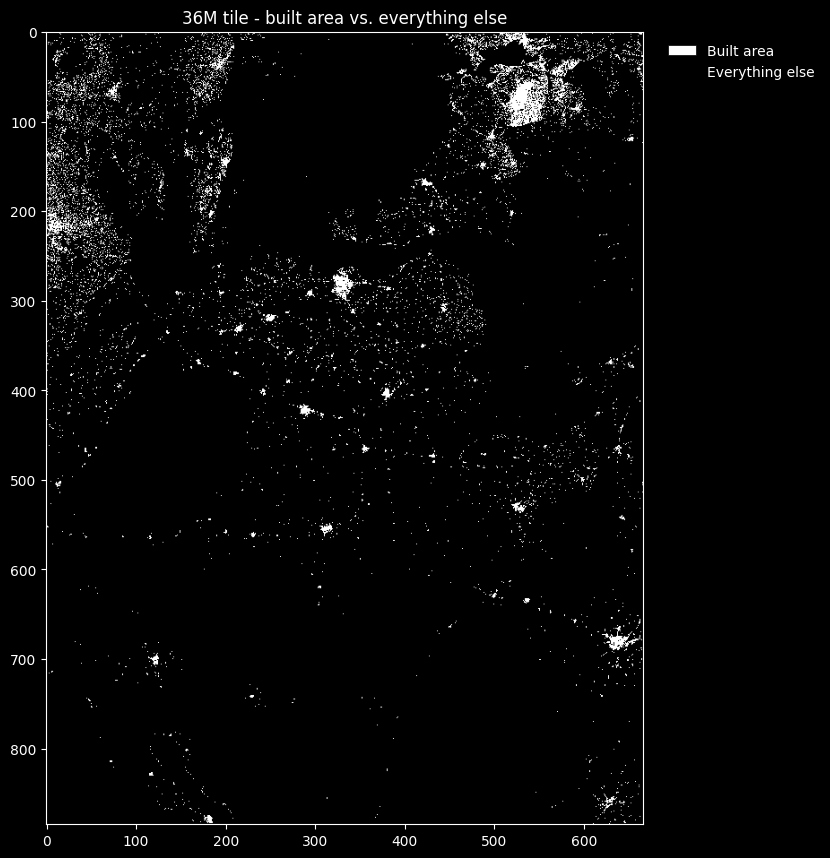

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

BUILT = 7   # Esri / Impact Observatory "Built area" class value

with rasterio.open(fp) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))

# binary mask: 1 = built area, 0 = everything else
binary = (thumb == BUILT).astype(np.uint8)

# 0 -> black, 1 -> white
bw = ListedColormap(['black', 'white'])

plt.figure(figsize=(8, 10))
plt.imshow(binary, cmap=bw, vmin=0, vmax=1)
plt.title('36M tile - built area vs. everything else')
plt.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Everything else'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
plt.tight_layout()
plt.show()

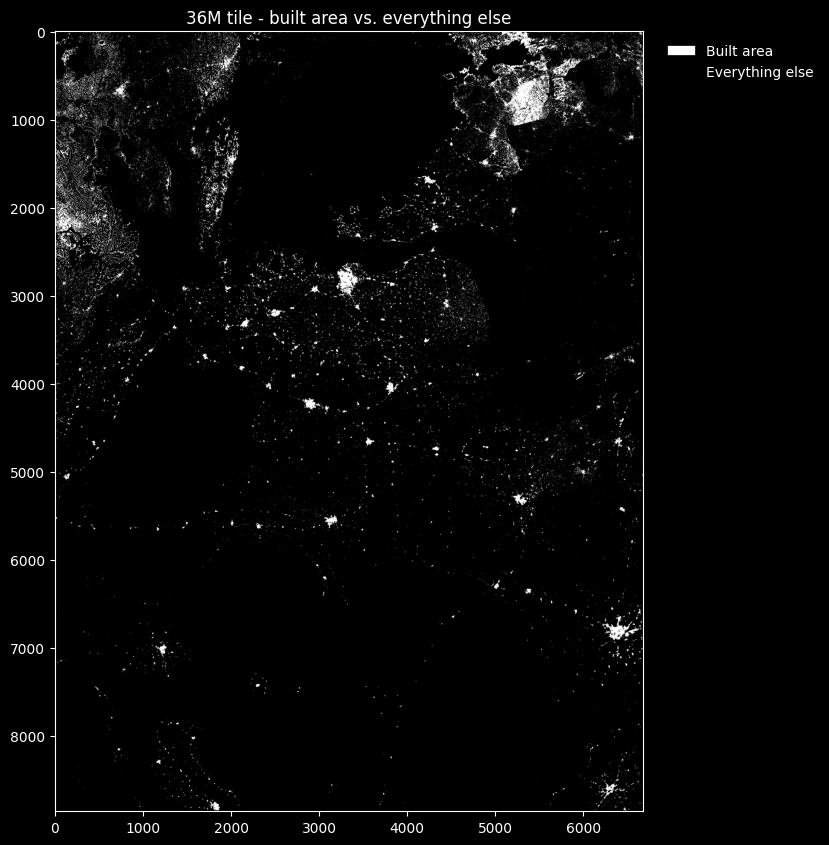

In [ ]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

BUILT = 7   # Esri / Impact Observatory "Built area" class value

with rasterio.open(fp) as ds:
    scale = 10
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))

# binary mask: 1 = built area, 0 = everything else
binary = (thumb == BUILT).astype(np.uint8)

# 0 -> black, 1 -> white
bw = ListedColormap(['black', 'white'])

plt.figure(figsize=(8, 10))
plt.imshow(binary, cmap=bw, vmin=0, vmax=1)
plt.title('36M tile - built area vs. everything else')
plt.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Everything else'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
plt.tight_layout()
plt.show()

In [ ]:
import geopandas as gpd
import rasterio
from rasterio.mask import mask

fp = r'C:/Users/HP/DataScience/06_capstone/resources/36M_20250101-20251231.tif'

kenya = gpd.read_file('data/raw/ke_shp/ke.shp')
boundary = kenya.dissolve()                     # one national polygon

with rasterio.open(fp) as ds:
    boundary = boundary.to_crs(ds.crs)          # match raster CRS (UTM 36S)
    geoms = [boundary.geometry.iloc[0]]
    clipped, clipped_transform = mask(ds, geoms, crop=True)
    meta = ds.meta.copy()
    cmap = ds.colormap(1)

meta.update(height=clipped.shape[1], width=clipped.shape[2],
            transform=clipped_transform)

with rasterio.open('data/processed/36M_kenya_clip.tif', 'w', **meta) as dst:
    dst.write(clipped)
    dst.write_colormap(1, cmap)                 # preserve the palette


In [ ]:
import os
import numpy as np
import geopandas as gpd
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.windows import Window, from_bounds
from rasterio.features import geometry_mask

RES = 'data/raw/classes'   # tiles live here now (moved from 06_capstone/resources)
OUT = 'data/processed'
os.makedirs(OUT, exist_ok=True)

# Tiles span 4 different UTM zones/hemispheres -> reproject all onto one grid.
TARGET_CRS = 'EPSG:32737'   # UTM zone 37S, metres (straddles equator, covers KE)

tiles = ['36M_20250101-20251231.tif', '36N_20250101-20251231.tif',
         '37M_20250101-20251231.tif', '37N_20250101-20251231.tif']
tile_paths = [os.path.join(RES, t) for t in tiles]

In [ ]:
for p in tile_paths:
    with rasterio.open(p) as ds:
        print(os.path.basename(p), ds.crs, ds.width, 'x', ds.height)


36M_20250101-20251231.tif EPSG:32736 66794 x 88550
36N_20250101-20251231.tif EPSG:32636 66794 x 88550
37M_20250101-20251231.tif EPSG:32737 66794 x 88550
37N_20250101-20251231.tif EPSG:32637 66794 x 88550


## Combine & Clip reference maps

### Approach — mosaic the four UTM tiles, then clip to Kenya

The UNDP product ships as four separate UTM-zone tiles (36M/36N/37M/37N), each in a
different CRS. To use them as one seamless label layer we must (1) reproject them to
a common CRS and (2) merge them. We do this with a **`WarpedVRT` + streamed merge to
disk** rather than loading everything into RAM, because the full mosaic is multiple
gigabytes and would not fit in memory. The result is then clipped to the Kenya
boundary in **row-blocks** for the same memory reason. Each cell below is one step of
that low-memory pipeline.

In [ ]:
# --- Mosaic: virtual reprojection (WarpedVRT) + streamed merge to disk ---
# WarpedVRT reprojects lazily (nothing materialised in RAM); merge(dst_path=...)
# streams the stitched output straight to disk. nearest = categorical classes.
# NOTE: driver='GTiff' MUST be set explicitly — without it merge() tries to write
# through the VRT source band and raises "Writing through VRTSourcedRasterBand is
# not supported". Takes ~22 min over the four full tiles.

srcs = [rasterio.open(p) for p in tile_paths]
vrts = [WarpedVRT(s, crs=TARGET_CRS, resampling=Resampling.nearest) for s in srcs]

cmap = srcs[0].colormap(1)   # palette to carry through to outputs

mosaic_path = os.path.join(OUT, 'kenya_landcover_mosaic.tif')

merge(
    vrts,
    dst_path=mosaic_path,
    dst_kwds={
        'driver': 'GTiff',      # REQUIRED with VRT sources (see note above)
        'compress': 'LZW',      # class rasters compress enormously
        'tiled': True,
        'blockxsize': 512,
        'blockysize': 512,
        'BIGTIFF': 'YES',       # mosaic exceeds the 4 GB TIFF limit
    },
    nodata=0,
    resampling=Resampling.nearest,
)

for v in vrts:
    v.close()
for s in srcs:
    s.close()

# merge() does not copy the palette — reattach it
with rasterio.open(mosaic_path, 'r+') as ds:
    ds.write_colormap(1, cmap)

print('mosaic written:', mosaic_path)

KeyboardInterrupt: 

In [ ]:
# --- Clip mosaic to Kenya, processed in row-blocks (low memory) ---
# Uses the complete boundary at data/raw/ke_shp/ke.shp (47 counties -> dissolve).
kenya = gpd.read_file('data/raw/ke_shp/ke.shp').dissolve().to_crs(TARGET_CRS)
kenya_geom = [kenya.geometry.iloc[0]]

clip_path = os.path.join(OUT, 'kenya_landcover_clipped.tif')

with rasterio.open(mosaic_path) as src:
    # window covering only Kenya's bounding box
    minx, miny, maxx, maxy = kenya.total_bounds
    win = from_bounds(minx, miny, maxx, maxy,
                      src.transform).round_offsets().round_lengths()
    win_w, win_h = int(win.width), int(win.height)

    profile = src.profile.copy()
    profile.update(
        height=win_h, width=win_w,
        transform=src.window_transform(win),
        compress='LZW', tiled=True, blockxsize=512, blockysize=512,
        BIGTIFF='YES', nodata=0,
    )

    with rasterio.open(clip_path, 'w', **profile) as dst:
        dst.write_colormap(1, cmap)
        block = 2048
        for row in range(0, win_h, block):
            h = min(block, win_h - row)
            src_win = Window(win.col_off, win.row_off + row, win_w, h)
            data = src.read(1, window=src_win)
            strip_transform = src.window_transform(src_win)
            # True where OUTSIDE the polygon -> set to nodata (0)
            outside = geometry_mask(kenya_geom, out_shape=(h, win_w),
                                    transform=strip_transform, invert=False)
            data[outside] = 0
            dst.write(data, 1, window=Window(0, row, win_w, h))

print('clipped to Kenya:', clip_path)

In [ ]:
# --- Preview the clipped result with the original palette ---
with rasterio.open(clip_path) as ds:
    scale = 100
    thumb = ds.read(1, out_shape=(ds.height // scale, ds.width // scale))
    cmap = ds.colormap(1)

# class value -> RGBA lookup table
lut = np.zeros((256, 4), dtype=np.uint8)
for v, rgba in cmap.items():
    lut[v] = rgba

# per-class pixel counts (excluding nodata=0) for the degradation analysis
vals, counts = np.unique(thumb, return_counts=True)
for v, c in zip(vals, counts):
    if v != 0:
        print(f'class {v:>3}: {c:>10,} px')

plt.figure(figsize=(10, 10))
plt.imshow(lut[thumb])
plt.title('Kenya land cover — mosaicked (UTM 37S), clipped')
plt.axis('off')
plt.show()

combined mosaic shape: (1791, 1340)


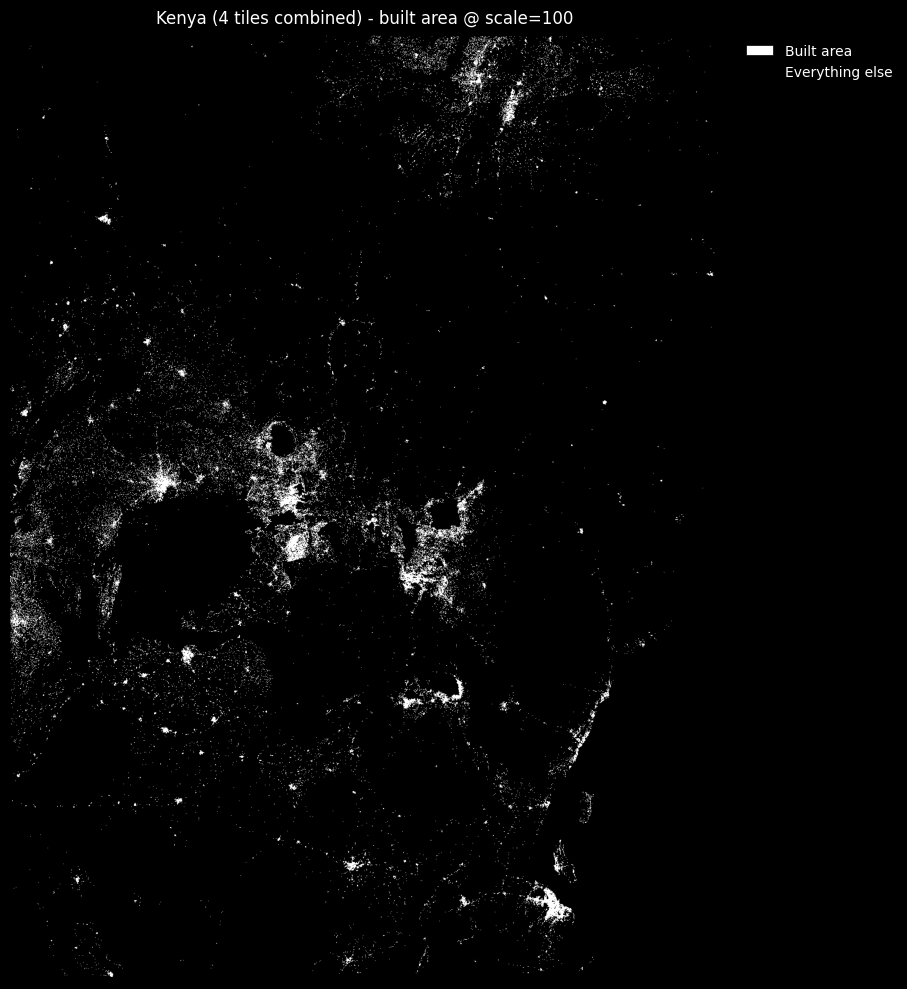

In [ ]:
# --- Combine all four tiles (downsampled) + built-area mask @ scale=100 ---
# Reproject each tile onto the common grid via WarpedVRT, then merge at a coarse
# resolution (10 m native * 100 = 1000 m) so the whole mosaic fits in memory and
# stitches in seconds instead of ~22 min at full res. nearest = categorical classes.
from rasterio.merge import merge
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

BUILT = 7          # Esri / Impact Observatory "Built area" class value
scale = 100
res = 10 * scale   # native pixel is 10 m -> 1000 m output pixels

srcs = [rasterio.open(p) for p in tile_paths]
vrts = [WarpedVRT(s, crs=TARGET_CRS, resampling=Resampling.nearest) for s in srcs]

mosaic, mosaic_transform = merge(vrts, res=res, nodata=0,
                                 resampling=Resampling.nearest)

for v in vrts:
    v.close()
for s in srcs:
    s.close()

mosaic = mosaic[0]                              # single band -> 2-D
print('combined mosaic shape:', mosaic.shape)

# binary mask: 1 = built area, 0 = everything else
binary = (mosaic == BUILT).astype(np.uint8)

bw = ListedColormap(['black', 'white'])         # 0 -> black, 1 -> white
plt.figure(figsize=(10, 10))
plt.imshow(binary, cmap=bw, vmin=0, vmax=1)
plt.title('Kenya (4 tiles combined) - built area @ scale=100')
plt.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Everything else'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
plt.axis('off')
plt.tight_layout()
plt.show()

built area    :   19,715 px  (~19,715 km2)
non-built land:  571,161 px  (~571,161 km2)


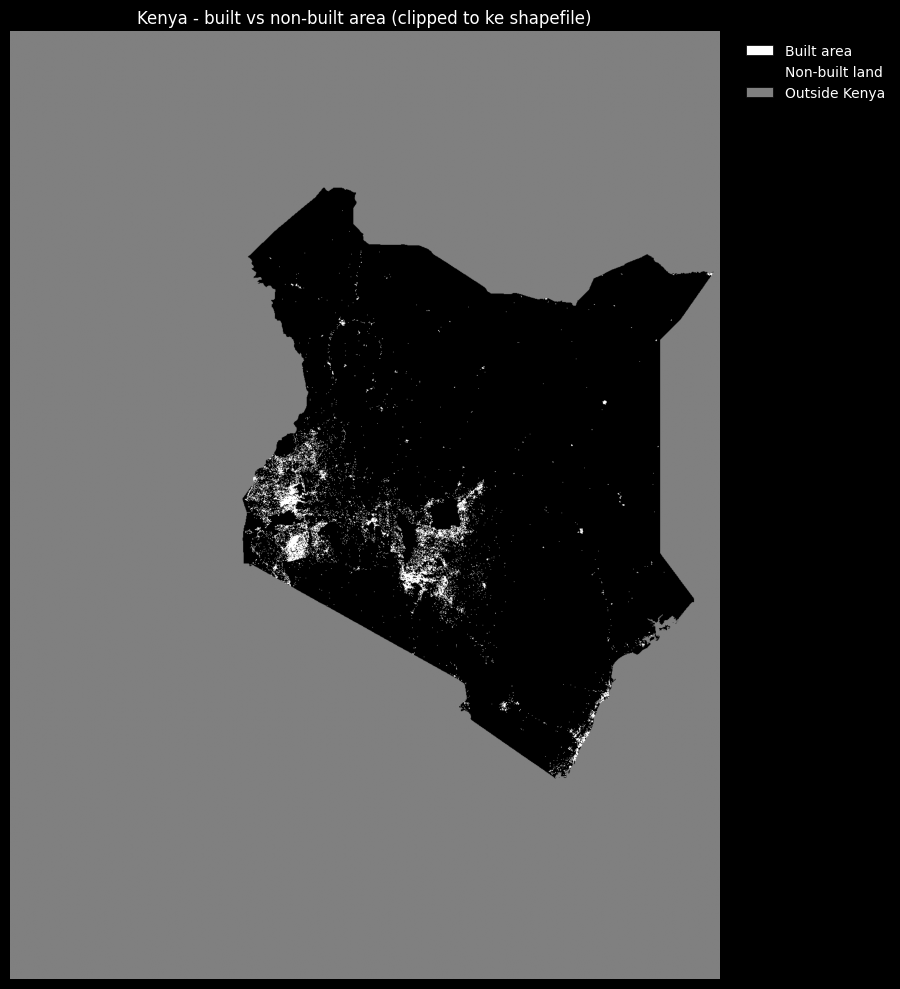

In [ ]:
# --- Clip the combined built-area mask to Kenya (ke shapefile) ---
# `binary` + `mosaic_transform` come from the cell above (UTM 37S grid).
# geometry_mask flags every pixel OUTSIDE the national polygon so we can show
# built / non-built only within Kenya and grey-out the rest.
kenya = gpd.read_file('data/raw/ke_shp/ke.shp').dissolve().to_crs(TARGET_CRS)
kenya_geom = [kenya.geometry.iloc[0]]

# True where OUTSIDE Kenya
outside = geometry_mask(kenya_geom, out_shape=binary.shape,
                        transform=mosaic_transform, invert=False)

# 0 = non-built, 1 = built, 2 = outside Kenya
disp = np.where(outside, 2, binary).astype(np.uint8)

# built vs non-built pixel counts within Kenya only
n_built = int((disp == 1).sum())
n_nonbuilt = int((disp == 0).sum())
px_km2 = (res / 1000) ** 2                       # each pixel is res x res metres
print(f'built area    : {n_built:>8,} px  (~{n_built * px_km2:,.0f} km2)')
print(f'non-built land: {n_nonbuilt:>8,} px  (~{n_nonbuilt * px_km2:,.0f} km2)')

cmap3 = ListedColormap(['black', 'white', 'grey'])  # 0, 1, 2
plt.figure(figsize=(10, 10))
plt.imshow(disp, cmap=cmap3, vmin=0, vmax=2)
plt.title('Kenya - built vs non-built area (clipped to ke shapefile)')
plt.legend(
    handles=[
        Patch(facecolor='white',     edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black',     edgecolor='black', linewidth=0.5, label='Non-built land'),
        Patch(facecolor='grey', edgecolor='black', linewidth=0.5, label='Outside Kenya'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
plt.axis('off')
plt.tight_layout()
plt.show()

scale=10 mosaic shape: (17906, 13396)
protected areas: 411 polygons


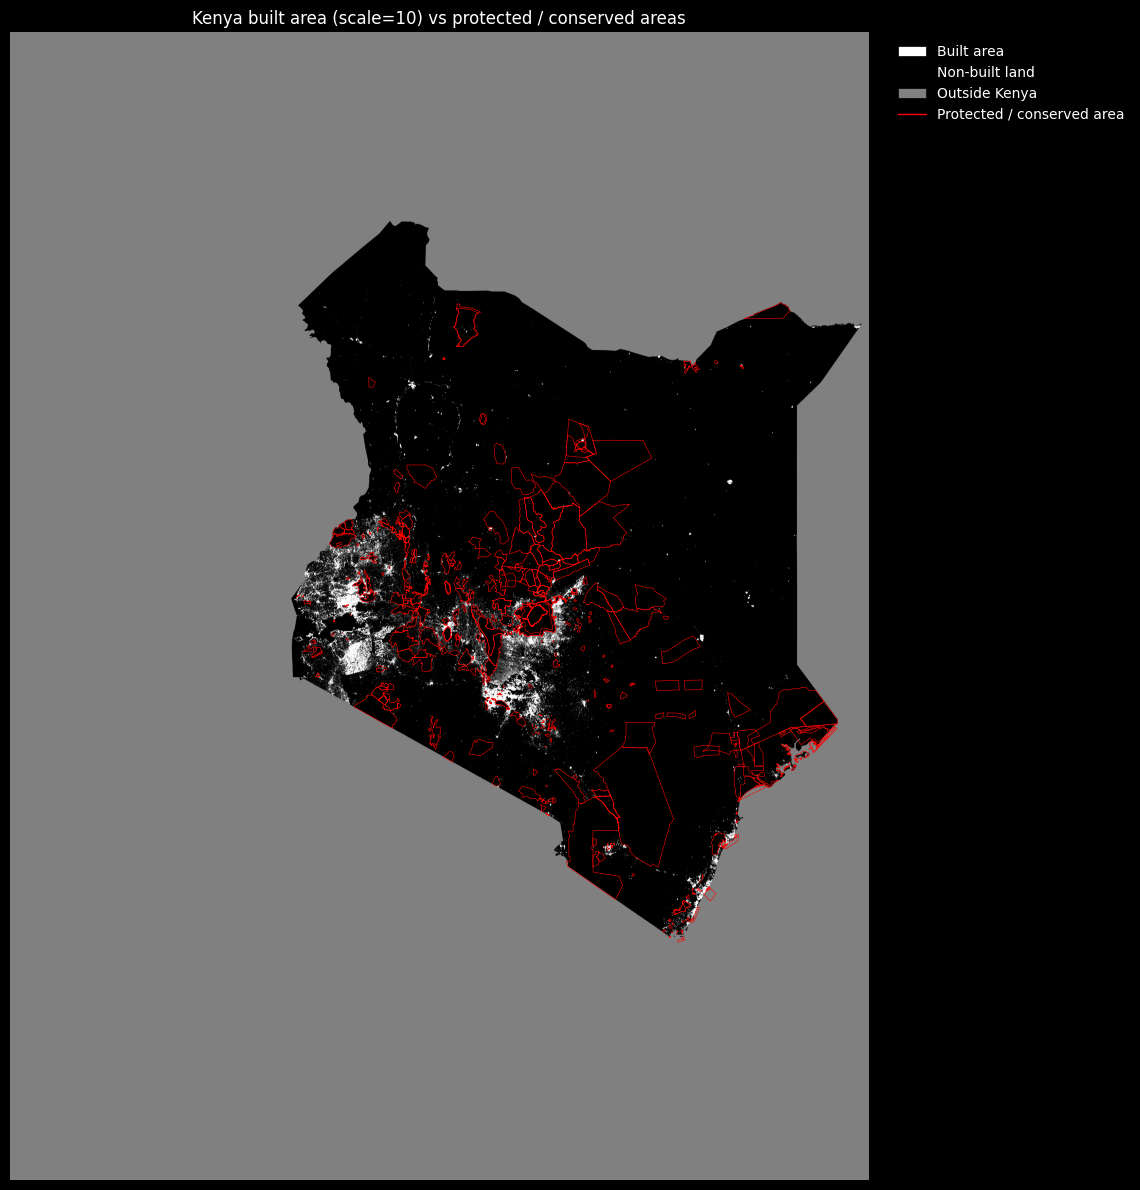

In [ ]:
# --- Kenya built-area mask @ scale=10, overlaid with protected/conserved areas ---
# Finer 100 m pixels (10 m native * 10) so you can see how close built area sits to
# protected-area boundaries. Rebuilds the mosaic at this resolution, clips to Kenya,
# then draws the WDPA/IUCN polygons on top using the raster's projected extent.
from rasterio.transform import array_bounds
from matplotlib.lines import Line2D

scale = 10
res = 10 * scale   # 100 m pixels

srcs = [rasterio.open(p) for p in tile_paths]
vrts = [WarpedVRT(s, crs=TARGET_CRS, resampling=Resampling.nearest) for s in srcs]
mosaic10, transform10 = merge(vrts, res=res, nodata=0, resampling=Resampling.nearest)
for v in vrts:
    v.close()
for s in srcs:
    s.close()
mosaic10 = mosaic10[0]
print('scale=10 mosaic shape:', mosaic10.shape)

# built mask + clip to Kenya (kenya_geom from the previous cell)
binary10 = (mosaic10 == BUILT).astype(np.uint8)
outside10 = geometry_mask(kenya_geom, out_shape=binary10.shape,
                          transform=transform10, invert=False)
disp10 = np.where(outside10, 2, binary10).astype(np.uint8)   # 0 non-built, 1 built, 2 outside

# protected / conserved area polygons -> reproject to the mosaic CRS
pa_path = (r'C:/Users/HP/DataScience/06_capstone/environmental-degradation-monitor/'
           r'data/raw/unep-wcmc and iucn protected areas/'
           r'protected_conserved_areas_wdpca_polygons.geojson')
pa = gpd.read_file(pa_path).to_crs(TARGET_CRS)
print('protected areas:', len(pa), 'polygons')

# projected extent of the raster so imshow and the vector overlay line up
west, south, east, north = array_bounds(*disp10.shape, transform10)

cmap3 = ListedColormap(['black', 'white', 'grey'])  # 0, 1, 2
fig, ax = plt.subplots(figsize=(11, 12))
ax.imshow(disp10, cmap=cmap3, vmin=0, vmax=2,
          extent=(west, east, south, north), origin='upper')
pa.boundary.plot(ax=ax, edgecolor='red', linewidth=0.4)
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title('Kenya built area (scale=10) vs protected / conserved areas')
ax.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Non-built land'),
        Patch(facecolor='grey',  edgecolor='black', linewidth=0.5, label='Outside Kenya'),
        Line2D([0], [0], color='red', linewidth=1, label='Protected / conserved area'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
ax.axis('off')
plt.tight_layout()
plt.show()

waterways: 50381 lines


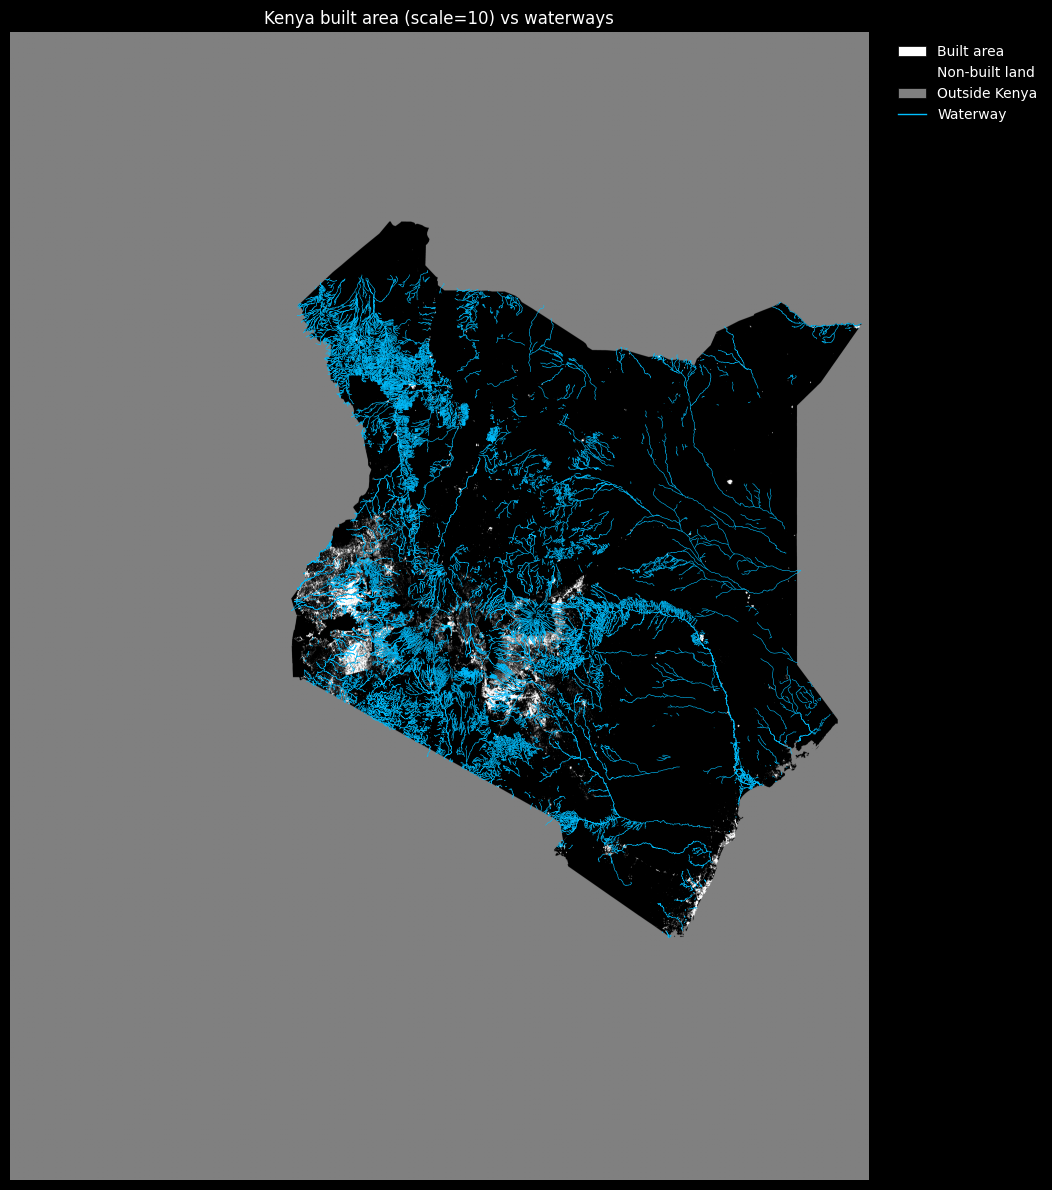

In [ ]:
# --- Kenya built-area mask @ scale=10, overlaid with waterways ---
# Reuses the scale=10 Kenya-clipped mask (disp10 / transform10) from the cell above
# and draws the HOTOSM/HDX waterway lines on top to show built area near water.
ww_path = (r'C:/Users/HP/DataScience/06_capstone/environmental-degradation-monitor/'
           r'data/raw/humdata/hotosm_ken_waterways_lines_geojson/'
           r'hotosm_ken_waterways_lines_geojson.geojson')
ww = gpd.read_file(ww_path).to_crs(TARGET_CRS)
print('waterways:', len(ww), 'lines')

# projected extent of the raster so imshow and the vector overlay line up
west, south, east, north = array_bounds(*disp10.shape, transform10)

cmap3 = ListedColormap(['black', 'white', 'grey'])  # 0 non-built, 1 built, 2 outside
fig, ax = plt.subplots(figsize=(11, 12))
ax.imshow(disp10, cmap=cmap3, vmin=0, vmax=2,
          extent=(west, east, south, north), origin='upper')
ww.plot(ax=ax, color='deepskyblue', linewidth=0.4)
ax.set_xlim(west, east)
ax.set_ylim(south, north)
ax.set_title('Kenya built area (scale=10) vs waterways')
ax.legend(
    handles=[
        Patch(facecolor='white', edgecolor='black', linewidth=0.5, label='Built area'),
        Patch(facecolor='black', edgecolor='black', linewidth=0.5, label='Non-built land'),
        Patch(facecolor='grey',  edgecolor='black', linewidth=0.5, label='Outside Kenya'),
        Line2D([0], [0], color='deepskyblue', linewidth=1, label='Waterway'),
    ],
    loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False,
)
ax.axis('off')
plt.tight_layout()
plt.show()

## Multi-class training labels, resolution-matched to satellite chips

Goal shift: train U-Net as **multi-class** semantic segmentation (all land-cover
classes, not just built/non-built), on labels reprojected onto whatever exact
pixel grid a downloaded satellite chip uses (10 m Sentinel-2, 30 m Landsat, etc.),
without clipping to the Kenya boundary. Built-area encroachment near protected
areas becomes a downstream step: run the trained model, isolate class 7 from the
per-pixel argmax, then compare against protected-area polygons over time.

Each cell below is a single, independently checkable step with printed/plotted
evidence, rather than one large function.

### Approach — resolution-matched, multi-class training labels

The goal now shifts from a single built-area mask to **full multi-class labels** that
line up pixel-for-pixel with the Sentinel-2 chips the model will actually see. The
strategy, one cell per step:

- **A** — audit each label tile for real signal (skip empty/nodata tiles) before use.
- **B** — restrict the working set to tiles that actually contain the target area.
- **C** — reproject a label tile onto an *arbitrary image's exact grid*, so every
  downloaded chip can be paired with a matching label (this is `get_label_for_image`).
- **D** — pick the resampling method from the target pixel size (nearest for
  categorical labels; never interpolate class indices).
- **E** — self-consistency test + visual proof on a placeholder chip.
- **F/G** — persist chip+label pairs with a manifest and track class balance.

This is the mechanism that makes future **Kenya fine-tuning** possible — the single
highest-value step for closing the domain-shift gap measured in `evaluation.ipynb`.

In [ ]:
# --- Cell A: tile usability report (live, read-only) ---
# Decimated per-tile class histogram so we know which tiles carry real signal
# before including them in the training pipeline. `tile_paths` (all 4 tiles)
# comes from the cell above (94e4f9f6). Verdicts here are the source of truth
# for Cell B -- do not hardcode a drop list, since all 4 tiles turn out to
# straddle Kenya's borders and each carries meaningful built-area coverage.

DECIMATE = 50  # read at 1/50 resolution per axis -> fast approximate histogram

CLASS_NAMES = {
    1: 'Water', 2: 'Trees', 4: 'Flooded vegetation', 5: 'Crops',
    7: 'Built area', 8: 'Bare ground', 9: 'Snow/ice', 10: 'Clouds', 11: 'Rangeland',
}

tile_report = []
print(f"{'tile':<28}{'crs':<10}{'valid %':>9}{'built % of valid':>19}  classes present")
for p in tile_paths:
    with rasterio.open(p) as ds:
        thumb = ds.read(1, out_shape=(ds.height // DECIMATE, ds.width // DECIMATE))
        crs_epsg = ds.crs.to_epsg()

    vals, counts = np.unique(thumb, return_counts=True)
    total = counts.sum()
    valid_total = counts[vals != 0].sum()
    valid_pct = 100 * valid_total / total
    built_count = int(counts[vals == BUILT].sum()) if BUILT in vals else 0
    built_pct = 100 * built_count / valid_total if valid_total else 0.0
    present = sorted(int(v) for v in vals if v != 0)
    verdict = 'KEEP' if (valid_pct > 5 and built_count > 0) else 'DROP'

    tile_report.append({'path': p, 'valid_pct': valid_pct, 'built_pct': built_pct,
                         'classes': present, 'verdict': verdict})
    print(f"{os.path.basename(p):<28}EPSG:{crs_epsg:<5}{valid_pct:>8.1f}%{built_pct:>18.2f}%  {present}  -> {verdict}")

In [ ]:
# --- Cell B: restrict working tile set to tiles with real signal ---
# Uses Cell A's live verdicts (do not hardcode which tiles to drop). No
# Kenya-boundary clipping: scope is whatever land the kept tiles cover (some
# spillover into neighbouring countries is fine -- Esri's LULC classes are
# defined the same way globally, so it's still valid training signal).
train_tile_paths = [d['path'] for d in tile_report if d['verdict'] == 'KEEP']

bounds_list = []
for p in train_tile_paths:
    with rasterio.open(p) as ds, WarpedVRT(ds, crs=TARGET_CRS, resampling=Resampling.nearest) as vrt:
        bounds_list.append(vrt.bounds)

xs = [b[0] for b in bounds_list] + [b[2] for b in bounds_list]
ys = [b[1] for b in bounds_list] + [b[3] for b in bounds_list]
combined_bounds = (min(xs), min(ys), max(xs), max(ys))

print('training tiles:', [os.path.basename(p) for p in train_tile_paths])
print(f'combined valid-data bounds ({TARGET_CRS}):', combined_bounds)

In [ ]:
# --- Cell C: reproject label tiles onto an arbitrary image's exact grid ---
# `image_path` is any satellite chip (e.g. downloaded from Copernicus Browser).
# Its own CRS/transform/shape become the target grid -- not an independently
# chosen one -- so the returned label lines up pixel-for-pixel with the image.
# Keeps RAW multi-class values (no binarizing to built/non-built).
def get_label_for_image(image_path, tile_paths, resampling):
    with rasterio.open(image_path) as img:
        dst_crs = img.crs
        dst_transform = img.transform
        dst_width, dst_height = img.width, img.height

    srcs = [rasterio.open(p) for p in tile_paths]
    vrts = [
        WarpedVRT(s, crs=dst_crs, resampling=resampling,
                  transform=dst_transform, width=dst_width, height=dst_height)
        for s in srcs
    ]

    label = np.zeros((dst_height, dst_width), dtype=np.uint8)
    for vrt in vrts:
        band = vrt.read(1)
        label = np.where(label == 0, band, label)  # first non-nodata tile wins

    for v in vrts: v.close()
    for s in srcs: s.close()

    return label, dst_transform

In [ ]:
# --- Cell D: choose the resampling method based on target pixel size ---
# Native land-cover resolution is 10 m. At or below that, nearest-neighbour is
# correct (categorical classes, no unnecessary aggregation). Above 10 m (e.g. a
# 30 m Landsat chip) each output pixel covers several native pixels, so use
# majority/mode resampling instead of nearest -- otherwise one arbitrary 10 m
# pixel gets picked per output pixel instead of the dominant class.
NATIVE_RES_M = 10

def choose_resampling(image_path):
    with rasterio.open(image_path) as img:
        px_size = abs(img.transform.a)
    method = Resampling.nearest if px_size <= NATIVE_RES_M else Resampling.mode
    print(f'{os.path.basename(image_path)}: pixel size = {px_size} m -> resampling = {method.name}')
    return method

In [ ]:
# --- Cell E: self-consistency test + visual proof (placeholder chip) ---
# No downloaded Sentinel-2/Landsat chip exists in the repo yet, so this proves
# the grid-matching machinery works by using a small window of a source tile as
# a stand-in "image": reading that window directly must equal
# get_label_for_image()'s output exactly. Once you have a real satellite chip,
# swap `stand_in_path` for its file path -- Cells C/D/F/G work unchanged.
test_path = train_tile_paths[0]  # 36M
with rasterio.open(test_path) as ds:
    win = Window(ds.width // 2 - 500, ds.height // 2 - 500, 1000, 1000)
    win_transform = ds.window_transform(win)
    direct = ds.read(1, window=win)
    stand_in_profile = ds.profile.copy()
    cmap = ds.colormap(1)

stand_in_path = os.path.join(OUT, 'stand_in_chip.tif')
stand_in_profile.update(height=1000, width=1000, transform=win_transform)
with rasterio.open(stand_in_path, 'w', **stand_in_profile) as dst:
    dst.write(direct, 1)

resampling = choose_resampling(stand_in_path)
label, label_transform = get_label_for_image(stand_in_path, train_tile_paths, resampling)

print('direct read shape     :', direct.shape)
print('function output shape :', label.shape)
print('shapes match           :', direct.shape == label.shape)
print('values identical       :', bool(np.array_equal(direct, label)))
print('transform matches      :', label_transform == win_transform)

vals, counts = np.unique(label, return_counts=True)
total = counts.sum()
for v, c in zip(vals, counts):
    if v != 0:
        print(f'{CLASS_NAMES.get(int(v), f"class {v}"):<20} {100 * c / total:.2f}%')

lut = np.zeros((256, 4), dtype=np.uint8)
for v, rgba in cmap.items():
    lut[v] = rgba

present = [v for v in np.unique(label) if v != 0]
handles = [
    Patch(facecolor=np.array(cmap[v]) / 255, edgecolor='black', linewidth=0.5,
          label=CLASS_NAMES.get(v, f'class {v}'))
    for v in present
]

plt.figure(figsize=(6, 6))
plt.imshow(lut[label])
plt.title('Multi-class label, matched to stand-in chip grid')
plt.axis('off')
plt.legend(handles=handles, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)
plt.tight_layout()
plt.show()

In [ ]:
# --- Cell F: persist chip pair + manifest ---
import csv

manifest_path = os.path.join(OUT, 'manifest.csv')
chip_id = 'stand_in_chip'
label_path = os.path.join(OUT, f'{chip_id}_label.tif')

label_profile = stand_in_profile.copy()
label_profile.update(dtype='uint8', count=1)
with rasterio.open(label_path, 'w', **label_profile) as dst:
    dst.write(label.astype(np.uint8), 1)

vals, counts = np.unique(label, return_counts=True)
total = counts.sum()
# cast to native float -- round() on a numpy float64 keeps it numpy, whose repr
# ("np.float64(0.95)") breaks ast.literal_eval when Cell G re-reads the CSV
class_pct = {int(v): round(100 * float(c) / float(total), 2)
             for v, c in zip(vals, counts) if v != 0}

write_header = not os.path.exists(manifest_path)
with open(manifest_path, 'a', newline='') as f:
    writer = csv.writer(f)
    if write_header:
        writer.writerow(['chip_id', 'image_path', 'label_path', 'source_tiles',
                          'resampling', 'pixel_size_m', 'class_pct'])
    writer.writerow([chip_id, stand_in_path, label_path,
                      ';'.join(os.path.basename(p) for p in train_tile_paths),
                      resampling.name, abs(win_transform.a), class_pct])

print('wrote label :', label_path)
print('manifest row appended to:', manifest_path)

In [ ]:
# --- Cell G: aggregate class balance across all chips collected so far ---
import ast
import pandas as pd

manifest = pd.read_csv(manifest_path)
totals = {}
for row in manifest['class_pct']:
    d = ast.literal_eval(row) if isinstance(row, str) else row
    for k, v in d.items():
        totals.setdefault(int(k), []).append(v)

print(f'{len(manifest)} chip(s) in manifest so far\n')
for cls, pcts in sorted(totals.items()):
    name = CLASS_NAMES.get(cls, f'class {cls}')
    print(f'{name:<20} mean {np.mean(pcts):.2f}%  (n={len(pcts)} chips)')